# YouTube Trending Videos (India) – Data Warehousing & Mining Project
This notebook analyses trending YouTube videos in **India** (`IN_youtube_trending_data.csv`). It covers:

1. Data loading & overview
2. Univariate analysis (distributions & box plots)
3. Channel & category analysis
4. Bivariate analysis & correlations
5. Time-series analysis
6. Top videos, engagement & interactivity
7. Regression (Simple & Multiple Linear Regression)
8. Classification (Decision Tree & Naïve Bayes) – predicting video popularity
9. Clustering (K-Means)

In [1]:
# Import required libraries
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine-learning libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, silhouette_score
)

# Set visualization style
sns.set_style("whitegrid")

# Display plots inside notebook
%matplotlib inline

## 1. Data Loading & Overview
In this section, we load the dataset and perform an initial inspection of its size, columns, and structural information.

In [2]:
# Load the CSV dataset (works in Colab, Jupyter or locally)
import os

candidate_paths = [
    '/content/IN_youtube_trending_data.csv',                 # Google Colab
    '/mnt/user-data/uploads/IN_youtube_trending_data.csv',   # uploaded location
    'IN_youtube_trending_data.csv',                          # current folder
]
DATA_PATH = next(p for p in candidate_paths if os.path.exists(p))

df = pd.read_csv(DATA_PATH)

# Display first 5 rows
df.head()

,video_id,title,publishedAt,channelId,channelTitle,categoryId,trending_date,tags,view_count,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,description
0,Iot0eF6EoNA,Sadak 2 | Official Trailer | Sanjay | Pooja | ...,2020-08-12T04:31:41Z,UCGqvJPRcv7aVFun-eTsatcA,FoxStarHindi,24,2020-08-12T00:00:00Z,sadak|sadak 2|mahesh bhatt|vishesh films|pooja...,9885899,224925,3979409,350210,https://i.ytimg.com/vi/Iot0eF6EoNA/default.jpg,False,False,Three Streams. Three Stories. One Journey. Sta...
1,x-KbnJ9fvJc,Kya Baat Aa : Karan Aujla (Official Video) Tan...,2020-08-11T09:00:11Z,UCm9SZAl03Rev9sFwloCdz1g,Rehaan Records,10,2020-08-12T00:00:00Z,[None],11308046,655450,33242,405146,https://i.ytimg.com/vi/x-KbnJ9fvJc/default.jpg,False,False,Singer/Lyrics: Karan Aujla Feat Tania Music/ D...
2,KX06ksuS6Xo,Diljit Dosanjh: CLASH (Official) Music Video |...,2020-08-11T07:30:02Z,UCZRdNleCgW-BGUJf-bbjzQg,Diljit Dosanjh,10,2020-08-12T00:00:00Z,clash diljit dosanjh|diljit dosanjh|diljit dos...,9140911,296533,6179,30058,https://i.ytimg.com/vi/KX06ksuS6Xo/default.jpg,False,False,CLASH official music video performed by DILJIT...
3,UsMRgnTcchY,Dil Ko Maine Di Kasam Video | Amaal M Ft.Ariji...,2020-08-10T05:30:49Z,UCq-Fj5jknLsUf-MWSy4_brA,T-Series,10,2020-08-12T00:00:00Z,hindi songs|2020 hindi songs|2020 new songs|t-...,23564512,743931,84162,136942,https://i.ytimg.com/vi/UsMRgnTcchY/default.jpg,False,False,Gulshan Kumar and T-Series presents Bhushan Ku...
4,WNSEXJJhKTU,"Baarish (Official Video) Payal Dev,Stebin Ben ...",2020-08-11T05:30:13Z,UCye6Oz0mg46S362LwARGVcA,VYRLOriginals,10,2020-08-12T00:00:00Z,VYRL Original|Mohsin Khan|Shivangi Joshi|Payal...,6783649,268817,8798,22984,https://i.ytimg.com/vi/WNSEXJJhKTU/default.jpg,False,False,VYRL Originals brings to you ‘Baarish’ - the b...


In [3]:
# Display number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

Number of rows: 251277
Number of columns: 16

Column Names:
['video_id', 'title', 'publishedAt', 'channelId', 'channelTitle', 'categoryId', 'trending_date', 'tags', 'view_count', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'description']


In [4]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 251277 entries, 0 to 251276
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   video_id           251277 non-null  str  
 1   title              251277 non-null  str  
 2   publishedAt        251277 non-null  str  
 3   channelId          251277 non-null  str  
 4   channelTitle       251276 non-null  str  
 5   categoryId         251277 non-null  int64
 6   trending_date      251277 non-null  str  
 7   tags               251277 non-null  str  
 8   view_count         251277 non-null  int64
 9   likes              251277 non-null  int64
 10  dislikes           251277 non-null  int64
 11  comment_count      251277 non-null  int64
 12  thumbnail_link     251277 non-null  str  
 13  comments_disabled  251277 non-null  bool 
 14  ratings_disabled   251277 non-null  bool 
 15  description        231822 non-null  str  
dtypes: bool(2), int64(5), str(9)
memory usage: 27.3 M

In [5]:
# Statistical summary of numerical columns
df.describe()

,categoryId,view_count,likes,dislikes,comment_count
count,251277.000000,2.512770e+05,2.512770e+05,2.512770e+05,2.512770e+05
mean,20.861448,2.793858e+06,1.389707e+05,2.333248e+03,8.246164e+03
std,6.040176,6.979626e+06,3.941973e+05,7.199925e+04,7.023638e+04
min,1.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,20.000000,3.779310e+05,1.204900e+04,0.000000e+00,3.420000e+02
50%,24.000000,9.474340e+05,3.699100e+04,0.000000e+00,1.123000e+03
75%,24.000000,2.420593e+06,1.161690e+05,7.180000e+02,3.951000e+03
max,29.000000,2.644074e+08,1.611524e+07,1.234147e+07,6.738565e+06


In [6]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
video_id                 0
title                    0
publishedAt              0
channelId                0
channelTitle             1
categoryId               0
trending_date            0
tags                     0
view_count               0
likes                    0
dislikes                 0
comment_count            0
thumbnail_link           0
comments_disabled        0
ratings_disabled         0
description          19455
dtype: int64


## 2. Univariate Analysis (Distributions & Box Plots)
We analyze the distributions and search for outliers in key metrics such as `view_count`, `likes`, and `comment_count`.

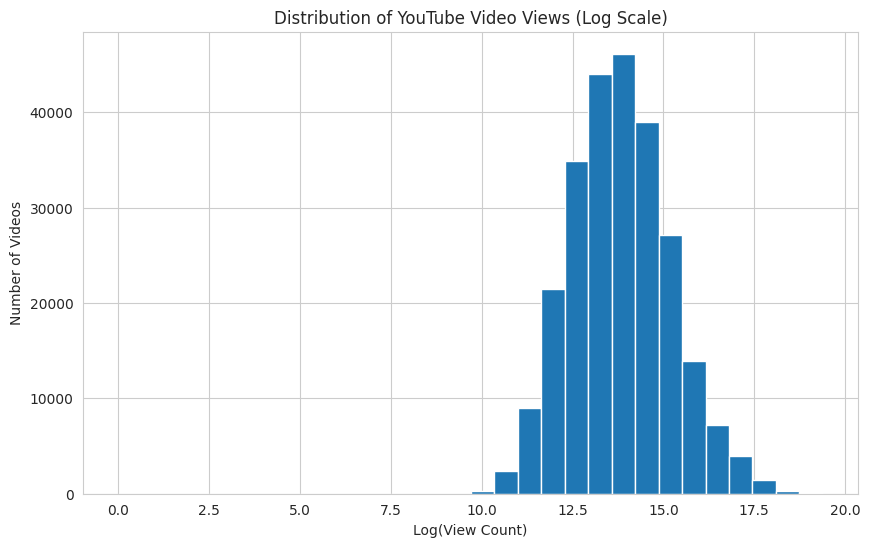

In [7]:
plt.figure(figsize=(10, 6))
plt.hist(np.log1p(df['view_count']), bins=30)
plt.title('Distribution of YouTube Video Views (Log Scale)')
plt.xlabel('Log(View Count)')
plt.ylabel('Number of Videos')
plt.show()

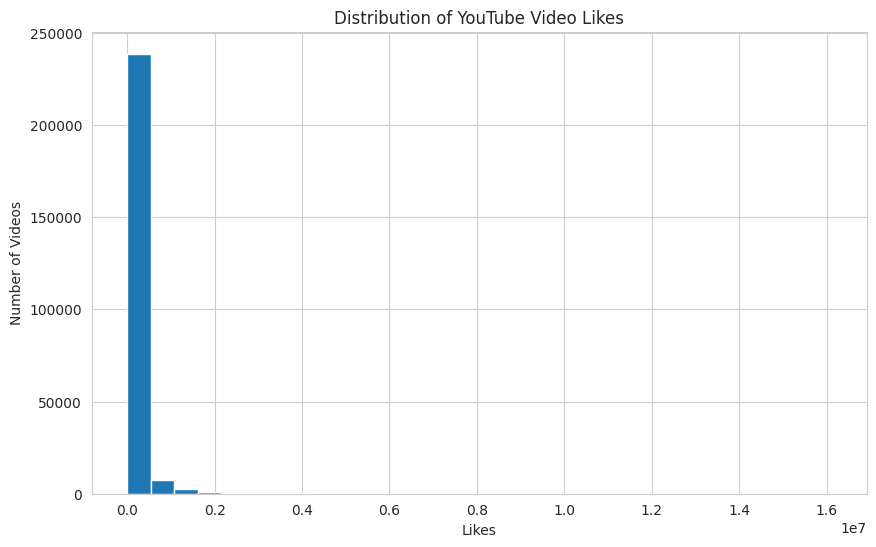

In [8]:
plt.figure(figsize=(10, 6))
plt.hist(df['likes'], bins=30)
plt.title('Distribution of YouTube Video Likes')
plt.xlabel('Likes')
plt.ylabel('Number of Videos')
plt.show()

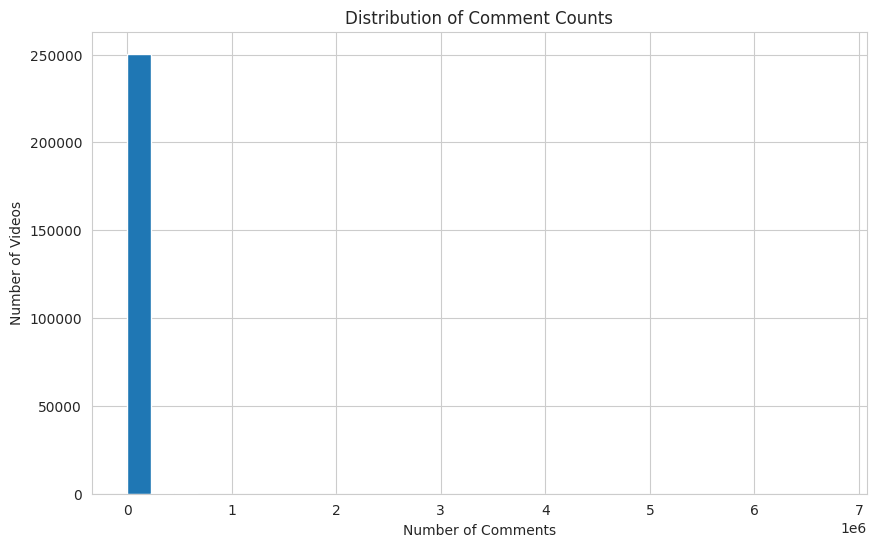

In [9]:
plt.figure(figsize=(10, 6))
plt.hist(df['comment_count'], bins=30)
plt.title('Distribution of Comment Counts')
plt.xlabel('Number of Comments')
plt.ylabel('Number of Videos')
plt.show()

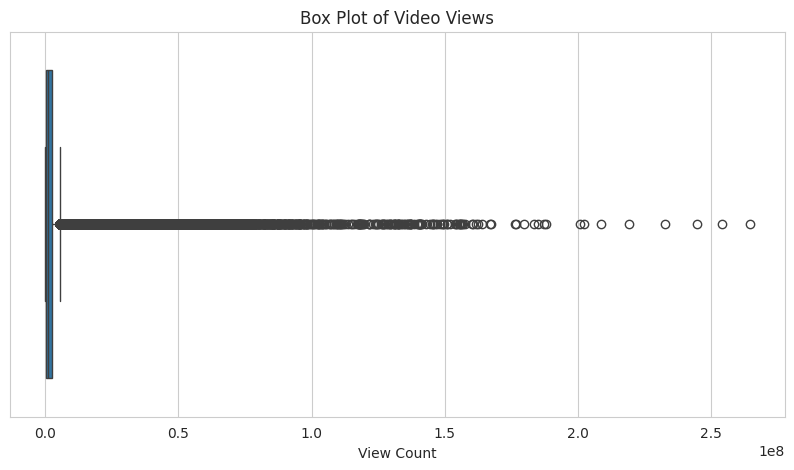

In [10]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['view_count'])
plt.title('Box Plot of Video Views')
plt.xlabel('View Count')
plt.show()

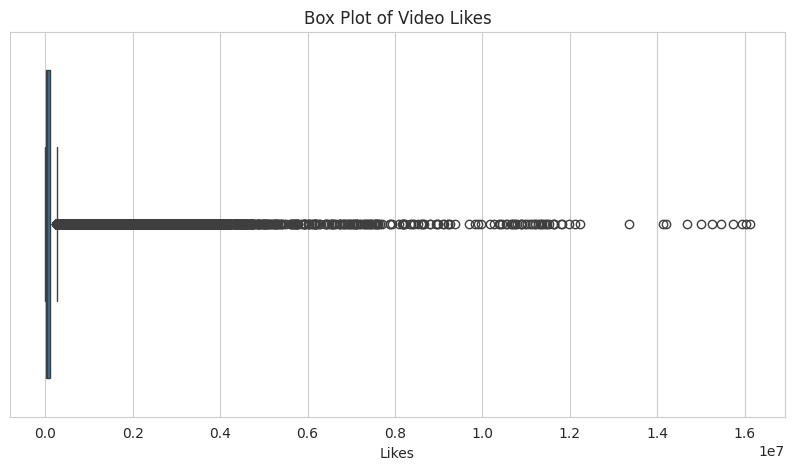

In [11]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['likes'])
plt.title('Box Plot of Video Likes')
plt.xlabel('Likes')
plt.show()

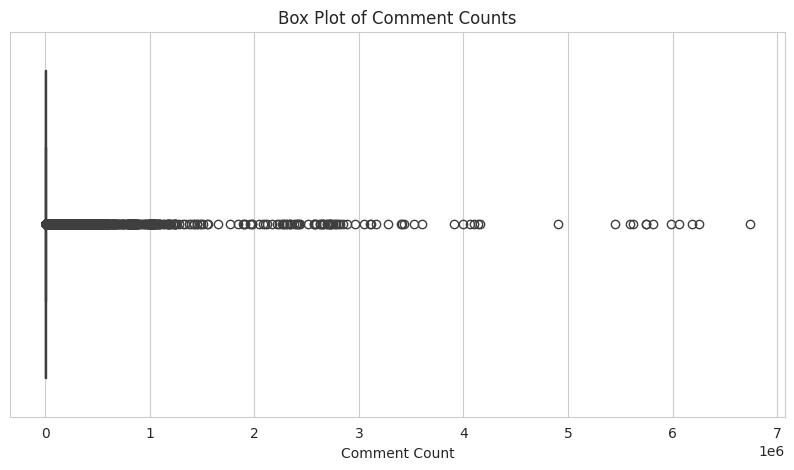

In [12]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['comment_count'])
plt.title('Box Plot of Comment Counts')
plt.xlabel('Comment Count')
plt.show()

## 3. Channel & Category Analysis
Let's explore which channels and video categories appear most frequently among trending videos and identify which ones average the most views.

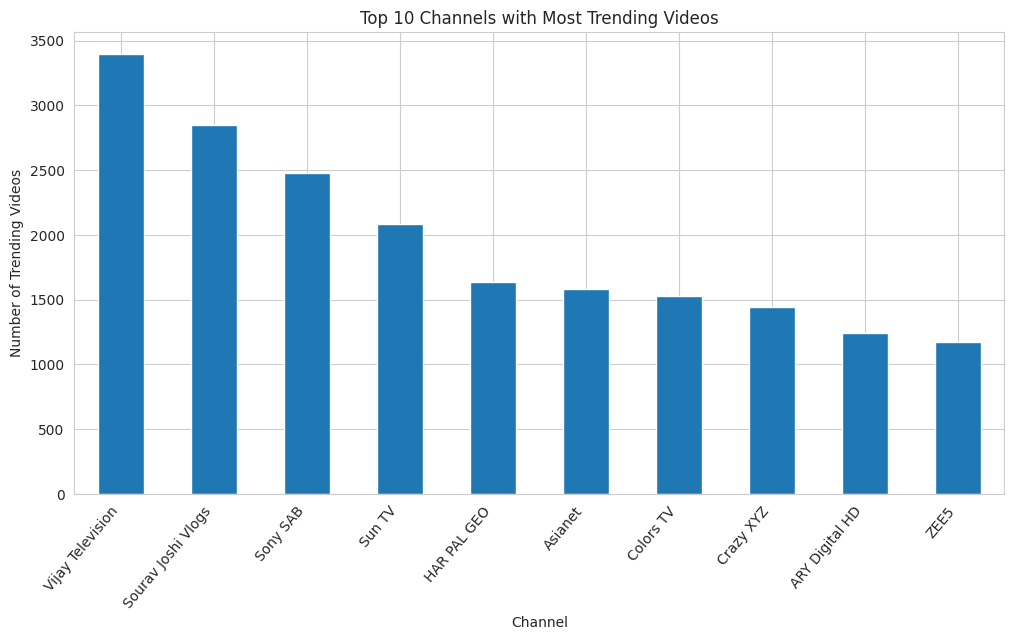

In [13]:
# Find top 10 channels based on number of trending videos
top_channels = df['channelTitle'].value_counts().head(10)

plt.figure(figsize=(12, 6))
top_channels.plot(kind='bar')
plt.title('Top 10 Channels with Most Trending Videos')
plt.xlabel('Channel')
plt.ylabel('Number of Trending Videos')
plt.xticks(rotation=50, ha='right')
plt.show()

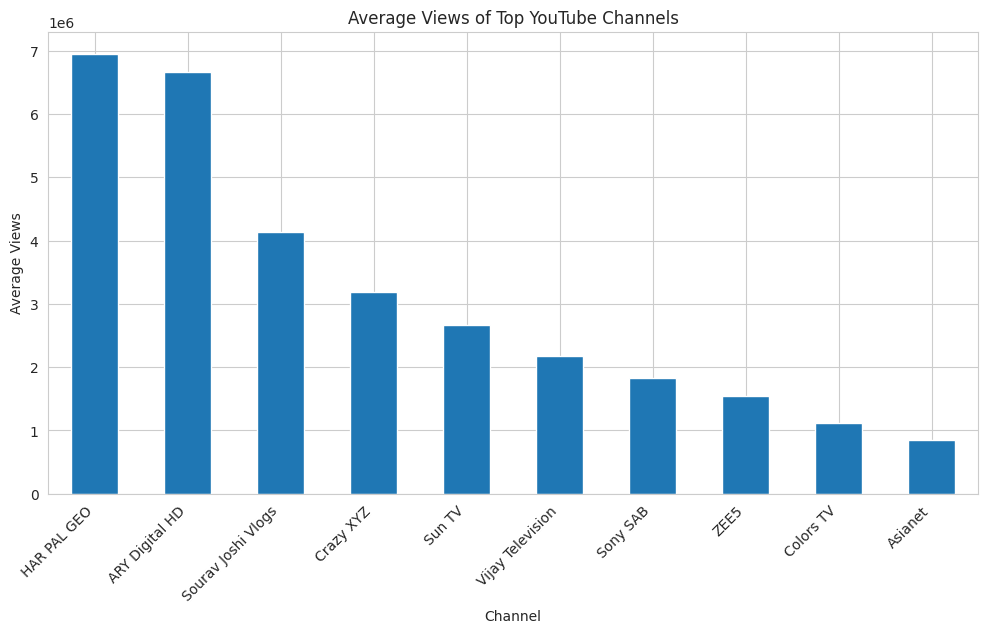

In [14]:
# Find channels with most videos
top_channels_list = df['channelTitle'].value_counts().head(10).index

# Filter dataset
channel_data = df[df['channelTitle'].isin(top_channels_list)]

# Calculate average views
avg_views = channel_data.groupby('channelTitle')['view_count'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
avg_views.plot(kind='bar')
plt.title('Average Views of Top YouTube Channels')
plt.xlabel('Channel')
plt.ylabel('Average Views')
plt.xticks(rotation=45, ha='right')
plt.show()

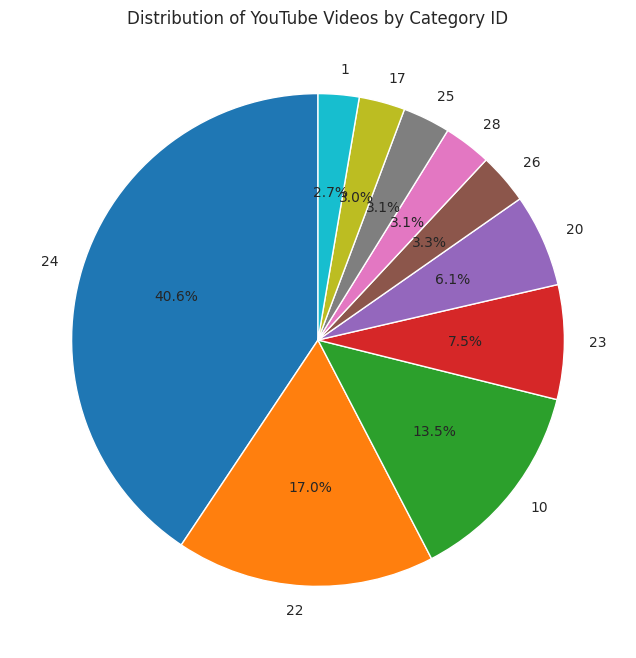

In [15]:
category_counts = df['categoryId'].value_counts().head(10)

plt.figure(figsize=(8, 8))
plt.pie(
    category_counts.values,
    labels=category_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Distribution of YouTube Videos by Category ID')
plt.show()

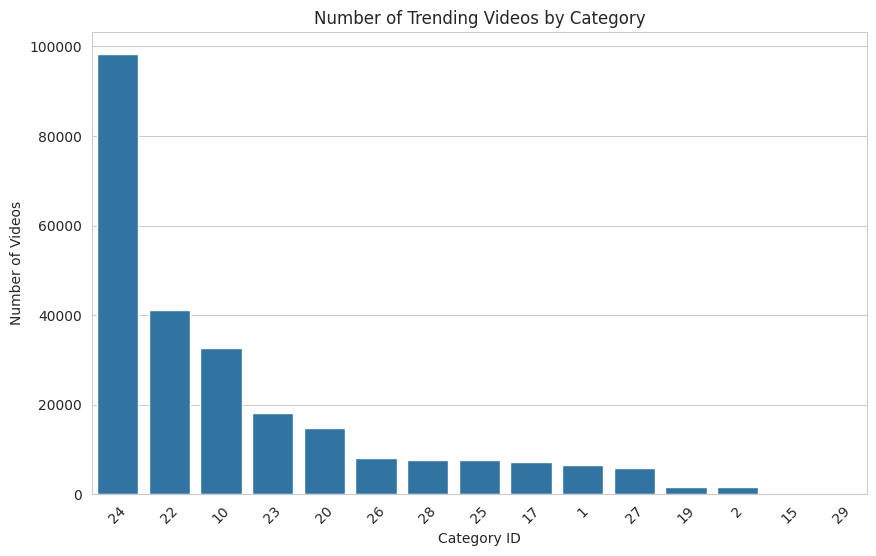

In [16]:
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    x='categoryId',
    order=df['categoryId'].value_counts().index
)
plt.title('Number of Trending Videos by Category')
plt.xlabel('Category ID')
plt.ylabel('Number of Videos')
plt.xticks(rotation=45)
plt.show()

## 4. Bivariate Analysis & Correlations
Here we analyze relationships and correlations between views, likes, dislikes, and comment counts using scatter plots and a correlation heatmap.

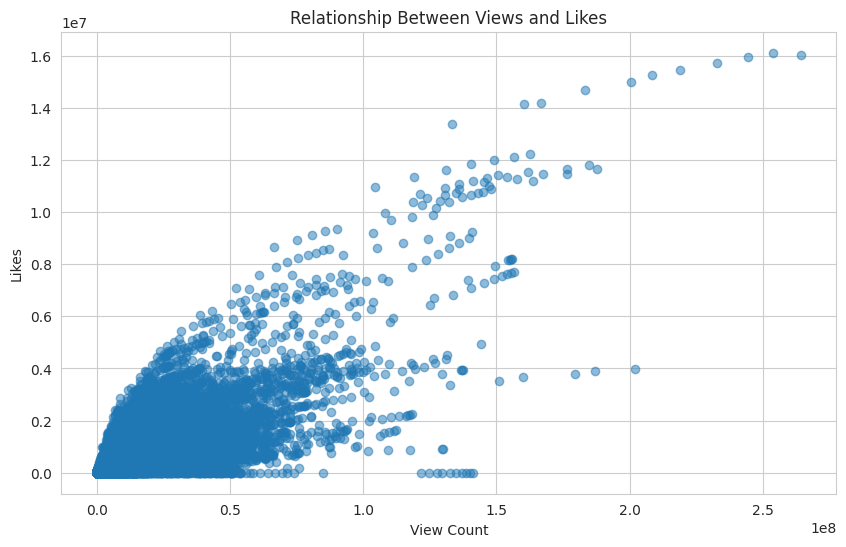

In [17]:
plt.figure(figsize=(10, 6))
plt.scatter(df['view_count'], df['likes'], alpha=0.5)
plt.title('Relationship Between Views and Likes')
plt.xlabel('View Count')
plt.ylabel('Likes')
plt.show()

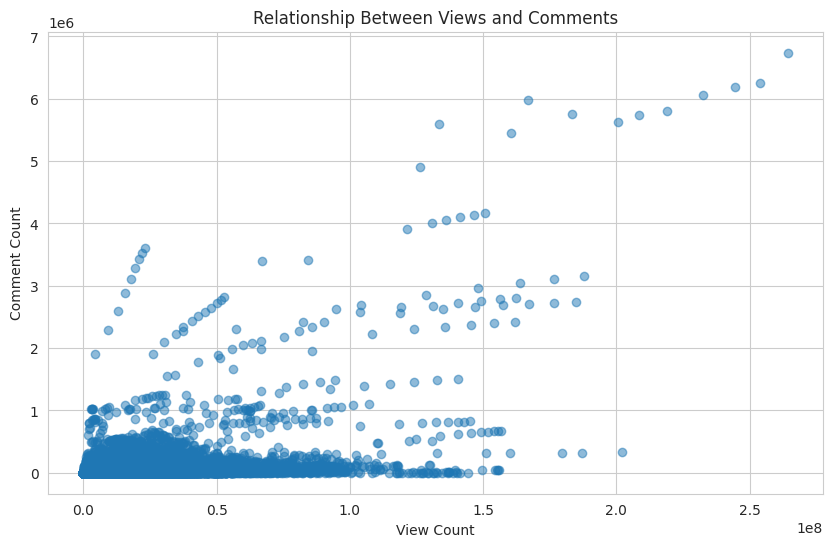

In [18]:
plt.figure(figsize=(10, 6))
plt.scatter(df['view_count'], df['comment_count'], alpha=0.5)
plt.title('Relationship Between Views and Comments')
plt.xlabel('View Count')
plt.ylabel('Comment Count')
plt.show()

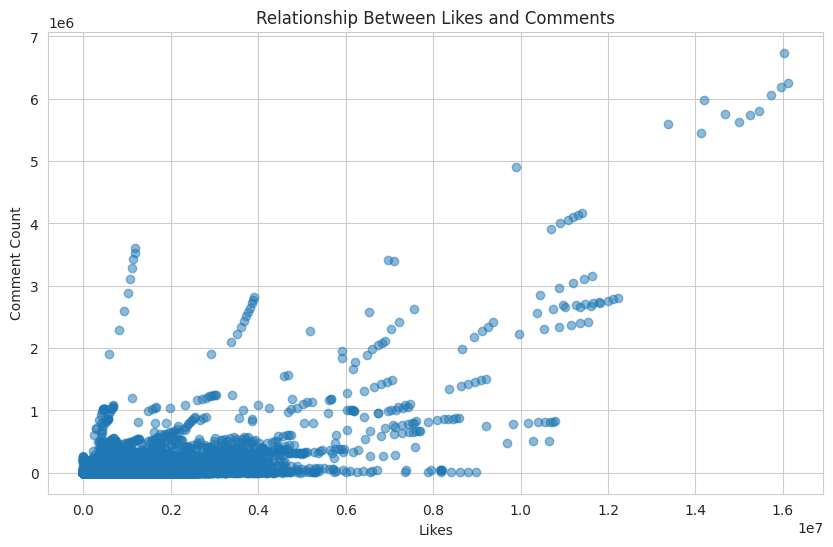

In [19]:
plt.figure(figsize=(10, 6))
plt.scatter(df['likes'], df['comment_count'], alpha=0.5)
plt.title('Relationship Between Likes and Comments')
plt.xlabel('Likes')
plt.ylabel('Comment Count')
plt.show()

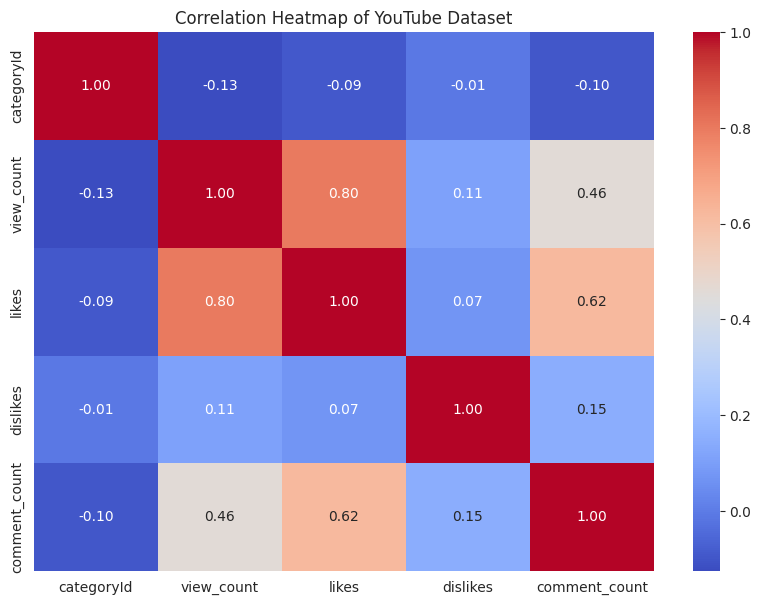

In [20]:
# Select numerical columns
numeric_columns = ['categoryId', 'view_count', 'likes', 'dislikes', 'comment_count']

correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of YouTube Dataset')
plt.show()

## 5. Time Series Analysis
We convert the date columns to datetime, then look at trends over time to see how both the total number of trending videos and average view counts fluctuate daily.

In [21]:
# Convert date columns to datetime
df['publishedAt'] = pd.to_datetime(df['publishedAt'])
df['trending_date'] = pd.to_datetime(df['trending_date'])

# Check the result
df[['publishedAt', 'trending_date']].head()

,publishedAt,trending_date
0,2020-08-12 04:31:41+00:00,2020-08-12 00:00:00+00:00
1,2020-08-11 09:00:11+00:00,2020-08-12 00:00:00+00:00
2,2020-08-11 07:30:02+00:00,2020-08-12 00:00:00+00:00
3,2020-08-10 05:30:49+00:00,2020-08-12 00:00:00+00:00
4,2020-08-11 05:30:13+00:00,2020-08-12 00:00:00+00:00


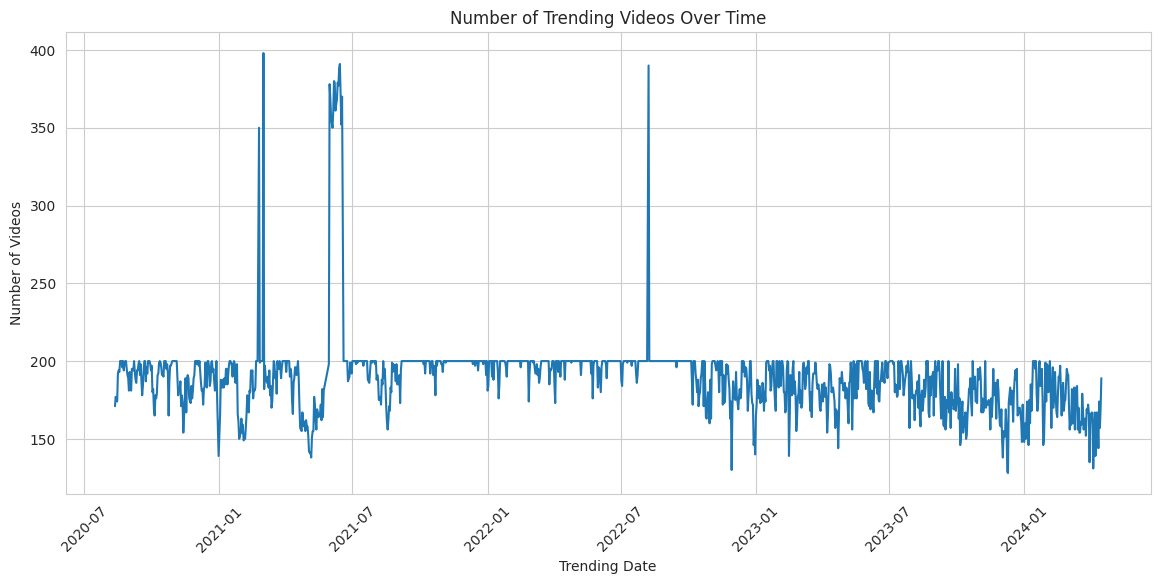

In [22]:
# Count videos for each trending date
daily_trending = df.groupby(df['trending_date'].dt.date).size()

plt.figure(figsize=(14, 6))
plt.plot(daily_trending.index, daily_trending.values)
plt.title('Number of Trending Videos Over Time')
plt.xlabel('Trending Date')
plt.ylabel('Number of Videos')
plt.xticks(rotation=45)
plt.show()

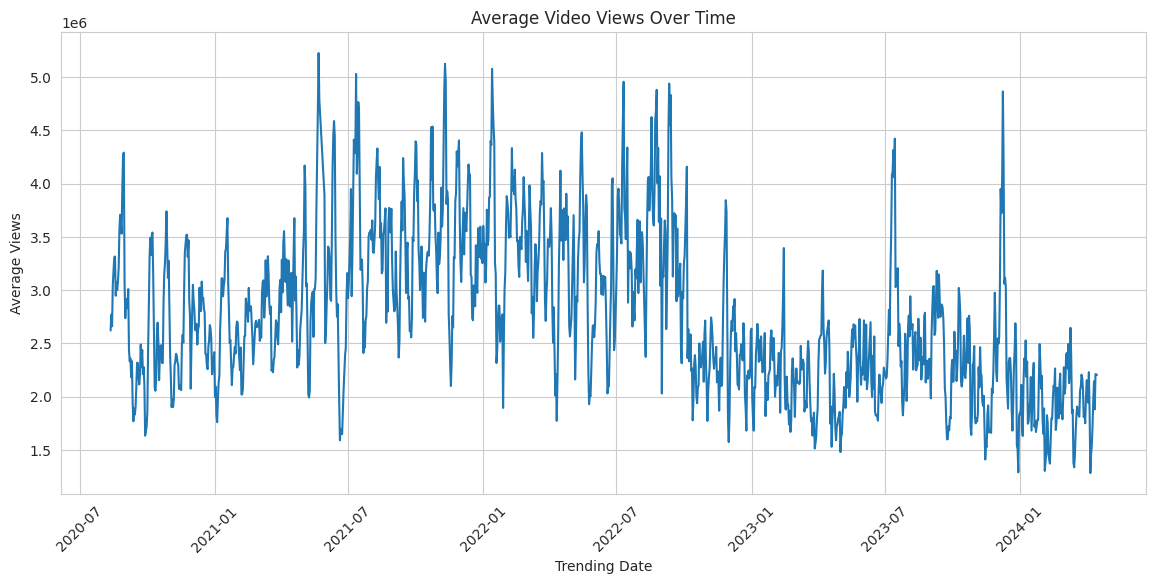

In [23]:
# Calculate average views for each trending date
daily_views = df.groupby(df['trending_date'].dt.date)['view_count'].mean()

plt.figure(figsize=(14, 6))
plt.plot(daily_views.index, daily_views.values)
plt.title('Average Video Views Over Time')
plt.xlabel('Trending Date')
plt.ylabel('Average Views')
plt.xticks(rotation=45)
plt.show()

## 6. Top Videos, Engagement, and Interactivity
We identify the top 10 most-viewed videos, analyze the user engagement rate, and check how often ratings or comments are disabled.

> A video can trend on many different days, so the same `video_id` appears in many rows. To avoid showing one video 10 times, we keep only the row with the highest view count for each video before taking the top 10.

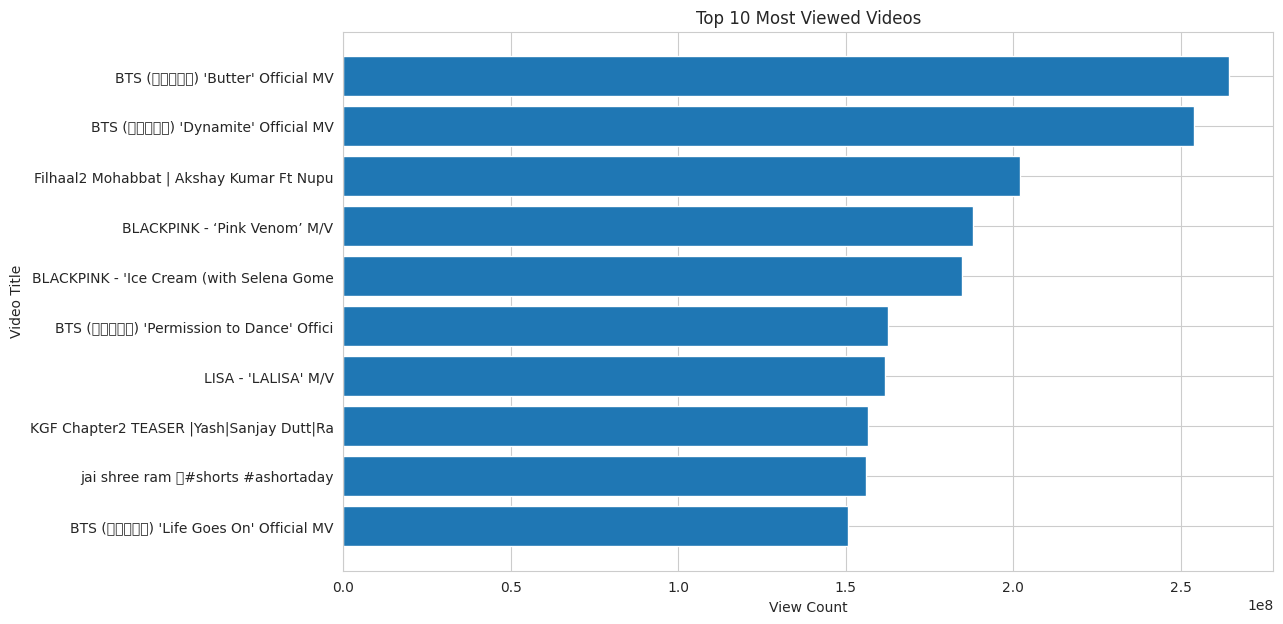

In [24]:
# Keep each video once (its highest view count), then take top 10
top_videos = (
    df.sort_values('view_count', ascending=False)
      .drop_duplicates(subset='video_id')
      .head(10)
)

plt.figure(figsize=(12, 7))
plt.barh(top_videos['title'].str[:40], top_videos['view_count'])
plt.title('Top 10 Most Viewed Videos')
plt.xlabel('View Count')
plt.ylabel('Video Title')
plt.gca().invert_yaxis()
plt.show()

In [25]:
df['engagement_rate'] = (df['likes'] + df['comment_count']) / df['view_count']

df['engagement_rate'].describe()

count    251261.000000
mean          0.056731
std           0.045636
min           0.000000
25%           0.020600
50%           0.045494
75%           0.080662
max           0.731755
Name: engagement_rate, dtype: float64

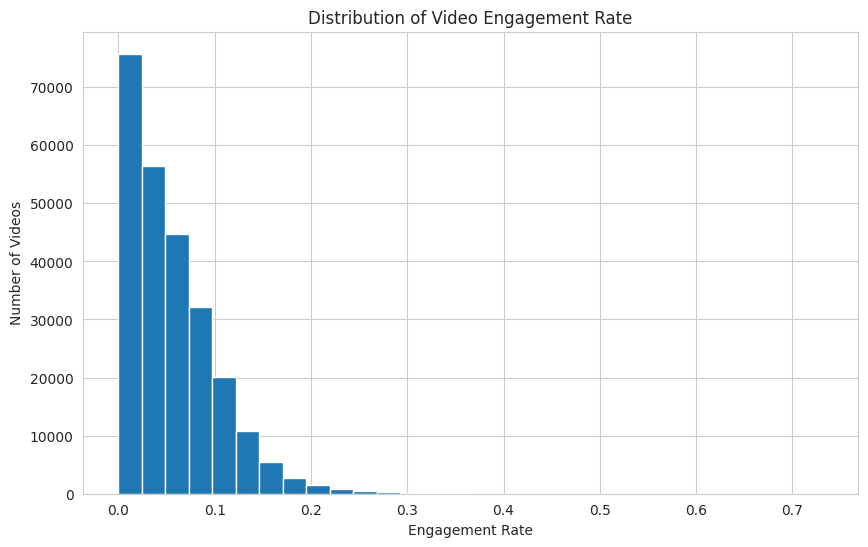

In [26]:
plt.figure(figsize=(10, 6))
plt.hist(df['engagement_rate'], bins=30)
plt.title('Distribution of Video Engagement Rate')
plt.xlabel('Engagement Rate')
plt.ylabel('Number of Videos')
plt.show()

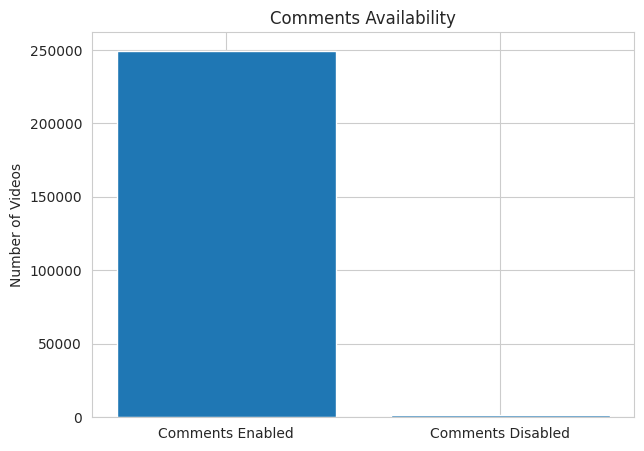

In [27]:
comment_status = df['comments_disabled'].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(
    ['Comments Enabled', 'Comments Disabled'],
    [comment_status.get(False, 0), comment_status.get(True, 0)]
)
plt.title('Comments Availability')
plt.ylabel('Number of Videos')
plt.show()

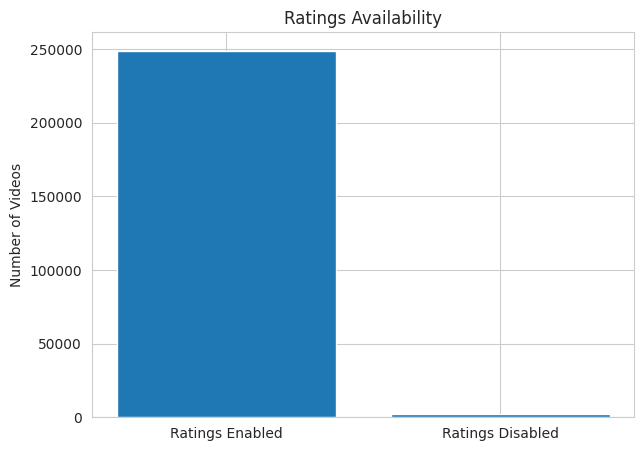

In [28]:
rating_status = df['ratings_disabled'].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(
    ['Ratings Enabled', 'Ratings Disabled'],
    [rating_status.get(False, 0), rating_status.get(True, 0)]
)
plt.title('Ratings Availability')
plt.ylabel('Number of Videos')
plt.show()

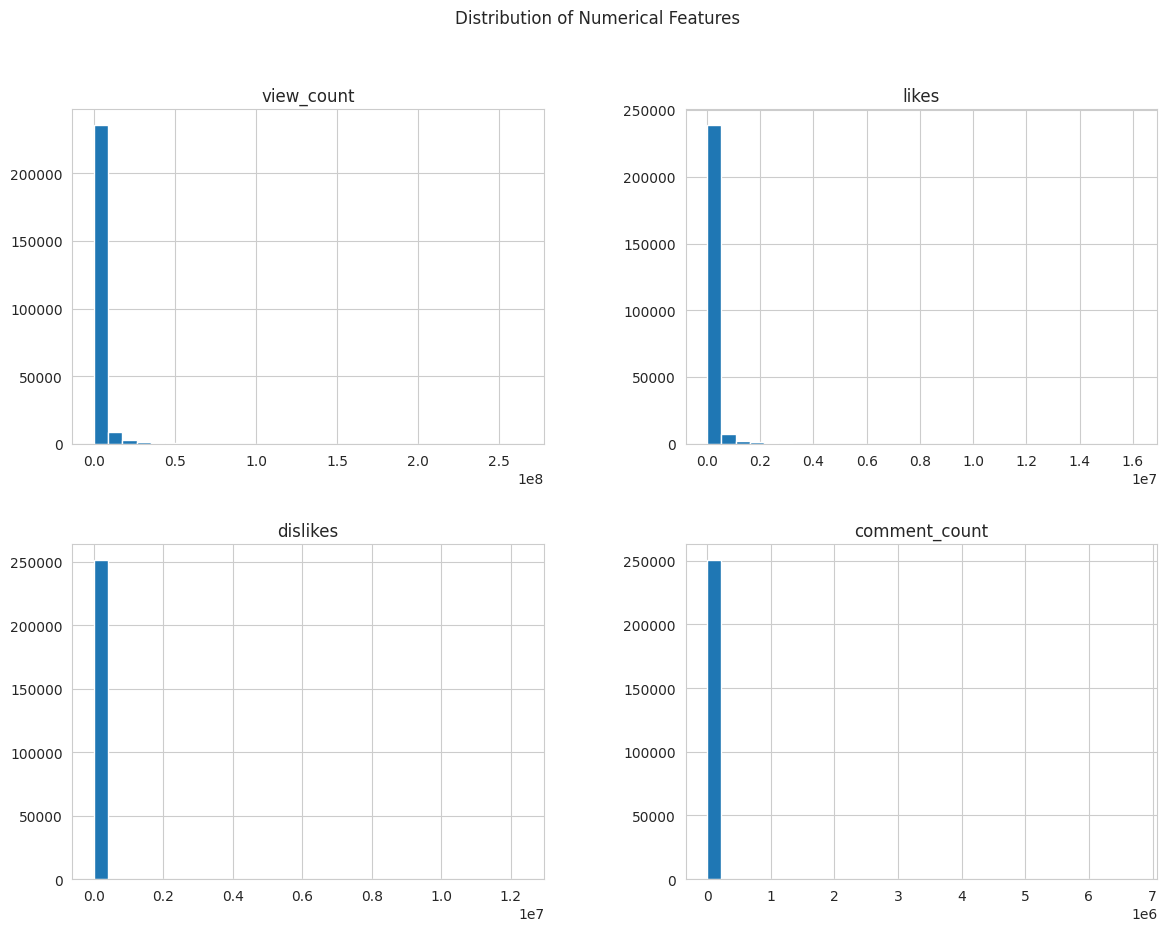

In [29]:
features = ['view_count', 'likes', 'dislikes', 'comment_count']

df[features].hist(figsize=(14, 10), bins=30)
plt.suptitle('Distribution of Numerical Features')
plt.show()

### Observations from Visualization
1. The dataset has 251,277 rows (78,847 unique videos) covering trending dates from August 2020 to April 2024. Each video can trend on several days, so rows are "trending appearances".
2. View counts are highly right-skewed: the median is about 0.95 million views while the maximum is about 264 million, so a few viral videos dominate the averages.
3. Likes and comments rise with views. Likes have the strongest correlation with views (about 0.80), comments are moderate (about 0.46) and dislikes are weak (about 0.11).
4. Box plots show a very large number of outliers in views, likes and comments.
5. A few channels (for example Vijay Television, Sourav Joshi Vlogs, Sony SAB and Sun TV) appear far more often than others, and many of them are TV or entertainment channels.
6. Category 24 (Entertainment) accounts for about 39% of trending rows, followed by 22 (People & Blogs) at about 16% and 10 (Music) at about 13%.
7. Roughly 190 videos trend per day on average, and the daily average view count fluctuates a lot because of viral videos.
8. The median engagement rate (likes + comments per view) is about 4.5%, and only about 0.7% of rows have comments disabled and about 0.9% have ratings disabled.

## 7. Regression Analysis
We now build **Simple Linear Regression** (likes → views) and **Multiple Linear Regression** (likes, dislikes, comments → views) models and compare them.

In [30]:
# Select columns required for regression
reg_df = df[['view_count', 'likes', 'dislikes', 'comment_count']].copy()

# Remove missing values
reg_df.dropna(inplace=True)

print("Shape:", reg_df.shape)
reg_df.head()

Shape: (251277, 4)


,view_count,likes,dislikes,comment_count
0,9885899,224925,3979409,350210
1,11308046,655450,33242,405146
2,9140911,296533,6179,30058
3,23564512,743931,84162,136942
4,6783649,268817,8798,22984


In [31]:
reg_df.corr()

,view_count,likes,dislikes,comment_count
view_count,1.000000,0.799752,0.110652,0.458001
likes,0.799752,1.000000,0.069301,0.619059
dislikes,0.110652,0.069301,1.000000,0.151245
comment_count,0.458001,0.619059,0.151245,1.000000


### 7.1 Simple Linear Regression

In [32]:
X = reg_df[['likes']]
y = reg_df['view_count']

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create model
slr = LinearRegression()

# Train model
slr.fit(X_train, y_train)

print("Simple Linear Regression model trained successfully!")

Simple Linear Regression model trained successfully!


In [33]:
y_pred_slr = slr.predict(X_test)

print("Actual values:")
print(y_test.head())

print("\nPredicted values:")
print(y_pred_slr[:5])

Actual values:
83989     54733865
226129     2525418
29774      2333227
84783       470369
43767      1092894
Name: view_count, dtype: int64

Predicted values:
[12687341.86070224  1376927.58321038  2621141.098493    1069868.44647027
  1670838.41416933]


In [34]:
mae_slr = mean_absolute_error(y_test, y_pred_slr)
mse_slr = mean_squared_error(y_test, y_pred_slr)
rmse_slr = np.sqrt(mse_slr)
r2_slr = r2_score(y_test, y_pred_slr)

print("Simple Linear Regression")
print("------------------------")
print("MAE  :", mae_slr)
print("MSE  :", mse_slr)
print("RMSE :", rmse_slr)
print("R2 Score :", r2_slr)

Simple Linear Regression
------------------------
MAE  : 1613652.3073303024
MSE  : 17343126160722.15
RMSE : 4164507.9133941084
R2 Score : 0.6282927301958853


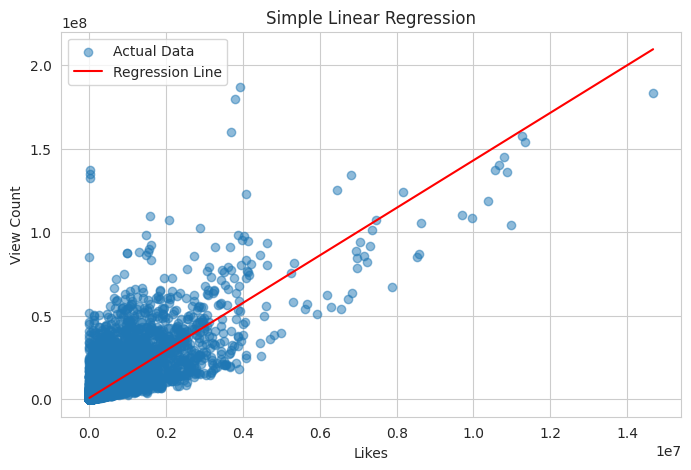

In [35]:
# Sort by X so that the regression line is drawn cleanly
order = np.argsort(X_test['likes'].values)

plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, alpha=0.5, label='Actual Data')
plt.plot(X_test['likes'].values[order], y_pred_slr[order], color='red', label='Regression Line')
plt.xlabel('Likes')
plt.ylabel('View Count')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

### 7.2 Multiple Linear Regression

In [36]:
X = reg_df[['likes', 'dislikes', 'comment_count']]
y = reg_df['view_count']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (201021, 3)
Testing data: (50256, 3)


In [37]:
mlr = LinearRegression()

mlr.fit(X_train, y_train)

print("Multiple Linear Regression model trained successfully!")

Multiple Linear Regression model trained successfully!


In [38]:
y_pred_mlr = mlr.predict(X_test)

print("Actual values:")
print(y_test.head())

print("\nPredicted values:")
print(y_pred_mlr[:5])

Actual values:
83989     54733865
226129     2525418
29774      2333227
84783       470369
43767      1092894
Name: view_count, dtype: int64

Predicted values:
[13149326.84048511  1340865.52019318  2638298.82745873  1033692.62335204
  1657996.53646804]


In [39]:
mae_mlr = mean_absolute_error(y_test, y_pred_mlr)
mse_mlr = mean_squared_error(y_test, y_pred_mlr)
rmse_mlr = np.sqrt(mse_mlr)
r2_mlr = r2_score(y_test, y_pred_mlr)

print("Multiple Linear Regression")
print("--------------------------")
print("MAE  :", mae_mlr)
print("MSE  :", mse_mlr)
print("RMSE :", rmse_mlr)
print("R2 Score :", r2_mlr)

Multiple Linear Regression
--------------------------
MAE  : 1596353.8594810567
MSE  : 17046010149054.518
RMSE : 4128681.4056129977
R2 Score : 0.6346606814227052


In [40]:
print("Intercept:", mlr.intercept_)

print("\nCoefficients:")
for feature, coefficient in zip(X.columns, mlr.coef_):
    print(feature, ":", coefficient)

Intercept: 768064.6551532722

Coefficients:
likes : 14.90177216018529
dislikes : 6.133295780886384
comment_count : -6.7878985769782565


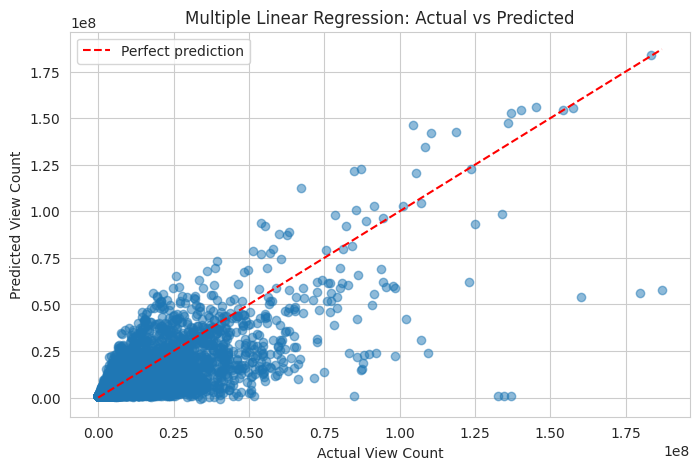

In [41]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_mlr, alpha=0.5)
# Ideal line (perfect prediction)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, color='red', linestyle='--', label='Perfect prediction')
plt.xlabel('Actual View Count')
plt.ylabel('Predicted View Count')
plt.title('Multiple Linear Regression: Actual vs Predicted')
plt.legend()
plt.show()

### 7.3 Model Comparison

In [42]:
reg_comparison = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'MAE': [mae_slr, mae_mlr],
    'RMSE': [rmse_slr, rmse_mlr],
    'R2 Score': [r2_slr, r2_mlr]
})

reg_comparison

,Model,MAE,RMSE,R2 Score
0,Simple Linear Regression,1.613652e+06,4.164508e+06,0.628293
1,Multiple Linear Regression,1.596354e+06,4.128681e+06,0.634661


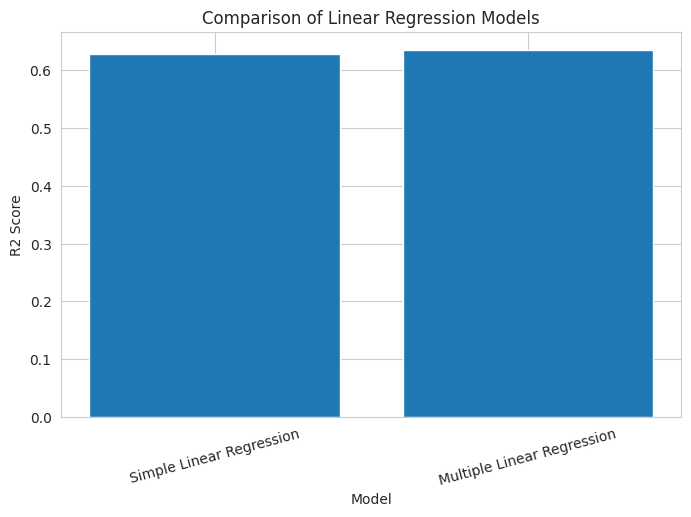

In [43]:
plt.figure(figsize=(8, 5))
plt.bar(reg_comparison['Model'], reg_comparison['R2 Score'])
plt.xlabel('Model')
plt.ylabel('R2 Score')
plt.title('Comparison of Linear Regression Models')
plt.xticks(rotation=15)
plt.show()

In [44]:
print("""
CONCLUSION:

Simple Linear Regression and Multiple Linear Regression were implemented
on the YouTube Trending dataset.

Simple Linear Regression used likes to predict view count, while Multiple
Linear Regression used likes, dislikes and comment count to predict view count.

The models were evaluated using MAE, RMSE and R2 Score. The performance
of both models was compared to understand the effect of using multiple
independent variables for prediction.
""")


CONCLUSION:

Simple Linear Regression and Multiple Linear Regression were implemented
on the YouTube Trending dataset.

Simple Linear Regression used likes to predict view count, while Multiple
Linear Regression used likes, dislikes and comment count to predict view count.

The models were evaluated using MAE, RMSE and R2 Score. The performance
of both models was compared to understand the effect of using multiple
independent variables for prediction.



## 8. Classification – Predicting Video Popularity
We label each video as **Popular** (views ≥ median) or **Not Popular**, analyse attribute relevance, and then train a **Decision Tree** and a **Naïve Bayes** classifier.

### 8.1 Creating the Target Variable

In [45]:
median_views = df['view_count'].median()

print("Median View Count:", median_views)

Median View Count: 947434.0


In [46]:
df['popularity'] = np.where(
    df['view_count'] >= median_views,
    'Popular',
    'Not Popular'
)

df[['view_count', 'popularity']].head(10)

,view_count,popularity
0,9885899,Popular
1,11308046,Popular
2,9140911,Popular
3,23564512,Popular
4,6783649,Popular
5,1699326,Popular
6,7363779,Popular
7,3816680,Popular
8,837562,Not Popular
9,1466612,Popular


In [47]:
print(df['popularity'].value_counts())

popularity
Popular        125639
Not Popular    125638
Name: count, dtype: int64


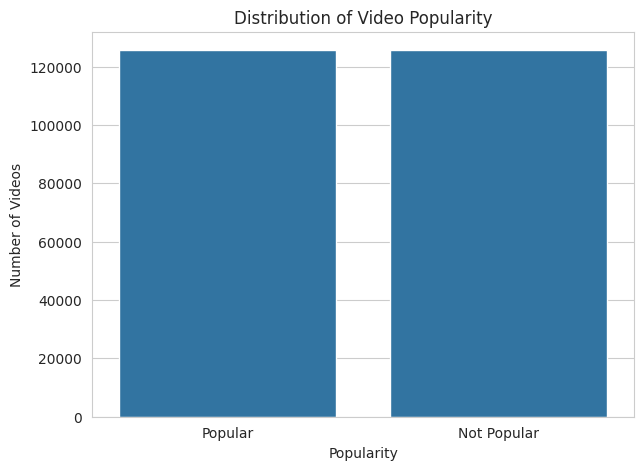

In [48]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='popularity')
plt.title('Distribution of Video Popularity')
plt.xlabel('Popularity')
plt.ylabel('Number of Videos')
plt.show()

### 8.2 Attribute Relevance Analysis

In [49]:
features = ['likes', 'dislikes', 'comment_count', 'categoryId']

analysis_df = df[features].copy()

analysis_df.head()

,likes,dislikes,comment_count,categoryId
0,224925,3979409,350210,24
1,655450,33242,405146,10
2,296533,6179,30058,10
3,743931,84162,136942,10
4,268817,8798,22984,10


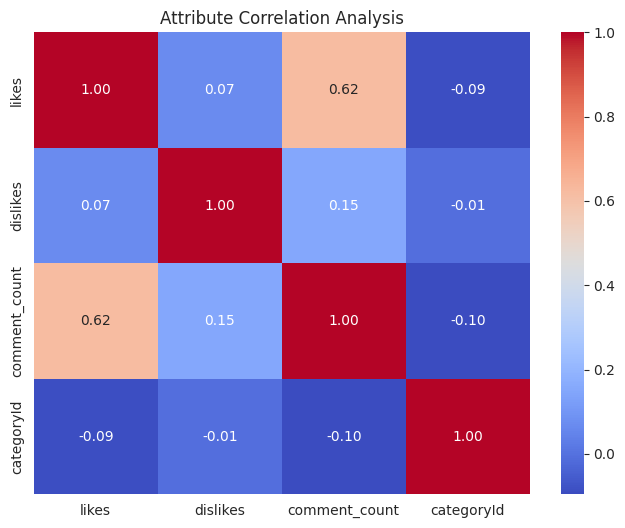

In [50]:
correlation = analysis_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Attribute Correlation Analysis')
plt.show()

In [51]:
df['popularity_numeric'] = df['popularity'].map({'Not Popular': 0, 'Popular': 1})

relevance = df[
    ['likes', 'dislikes', 'comment_count', 'categoryId', 'popularity_numeric']
].corr()['popularity_numeric'].drop('popularity_numeric')

print("Attribute Relevance with Popularity:")
print(relevance.sort_values(ascending=False))

Attribute Relevance with Popularity:
likes            0.295884
comment_count    0.099484
dislikes         0.027963
categoryId      -0.081790
Name: popularity_numeric, dtype: float64


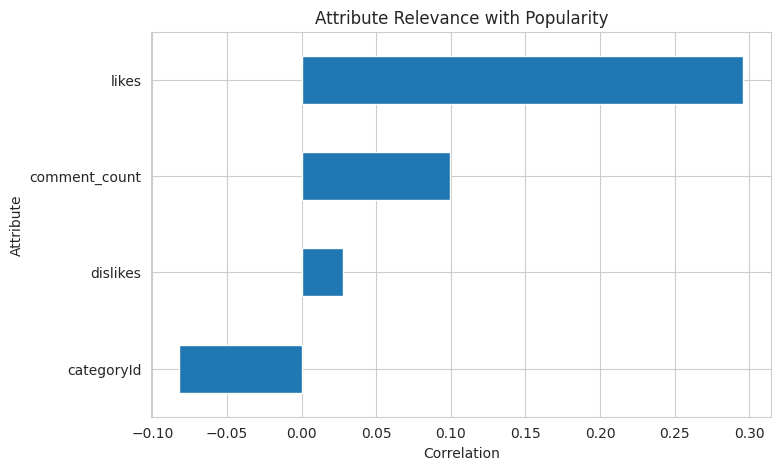

In [52]:
plt.figure(figsize=(8, 5))
relevance.sort_values().plot(kind='barh')
plt.title('Attribute Relevance with Popularity')
plt.xlabel('Correlation')
plt.ylabel('Attribute')
plt.show()

### 8.3 Data Preparation

In [53]:
X = df[['likes', 'dislikes', 'comment_count', 'categoryId']]
y = df['popularity']

In [54]:
print(X.isnull().sum())
print(y.isnull().sum())

likes            0
dislikes         0
comment_count    0
categoryId       0
dtype: int64
0


In [55]:
model_df = pd.concat([X, y], axis=1)

model_df.dropna(inplace=True)

X = model_df[['likes', 'dislikes', 'comment_count', 'categoryId']]
y = model_df['popularity']

print("Final dataset shape:", X.shape)

Final dataset shape: (251277, 4)


In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 201021
Testing samples: 50256


### 8.4 Decision Tree Classifier

In [57]:
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [58]:
y_pred = dt_model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
['Popular' 'Popular' 'Popular' 'Not Popular' 'Not Popular' 'Not Popular'
 'Not Popular' 'Popular' 'Not Popular' 'Popular']


In [59]:
dt_comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

dt_comparison.head(10)

,Actual,Predicted
0,Popular,Popular
1,Popular,Popular
2,Popular,Popular
3,Not Popular,Not Popular
4,Not Popular,Not Popular
5,Not Popular,Not Popular
6,Not Popular,Not Popular
7,Popular,Popular
8,Not Popular,Not Popular
9,Popular,Popular


In [60]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.8224291626870424
Accuracy (%): 82.24291626870423


In [61]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

 Not Popular       0.78      0.90      0.84     25128
     Popular       0.88      0.74      0.81     25128

    accuracy                           0.82     50256
   macro avg       0.83      0.82      0.82     50256
weighted avg       0.83      0.82      0.82     50256



In [62]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[22685  2443]
 [ 6481 18647]]


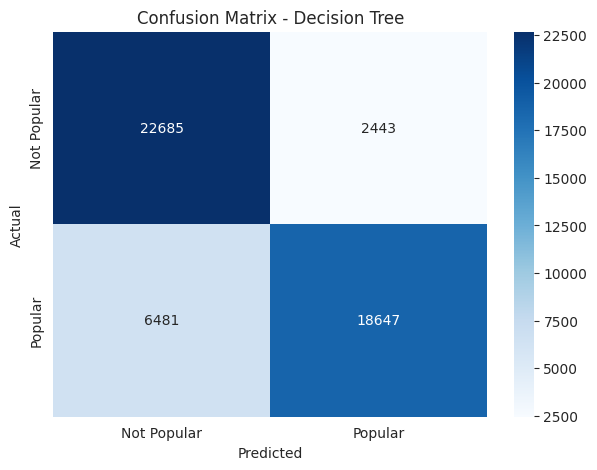

In [63]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Not Popular', 'Popular'],
    yticklabels=['Not Popular', 'Popular']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Decision Tree')
plt.show()

In [64]:
importance = pd.DataFrame({
    'Attribute': X.columns,
    'Importance': dt_model.feature_importances_
})

importance = importance.sort_values(by='Importance', ascending=False)

print(importance)

       Attribute  Importance
0          likes    0.893341
1       dislikes    0.054081
3     categoryId    0.046003
2  comment_count    0.006574


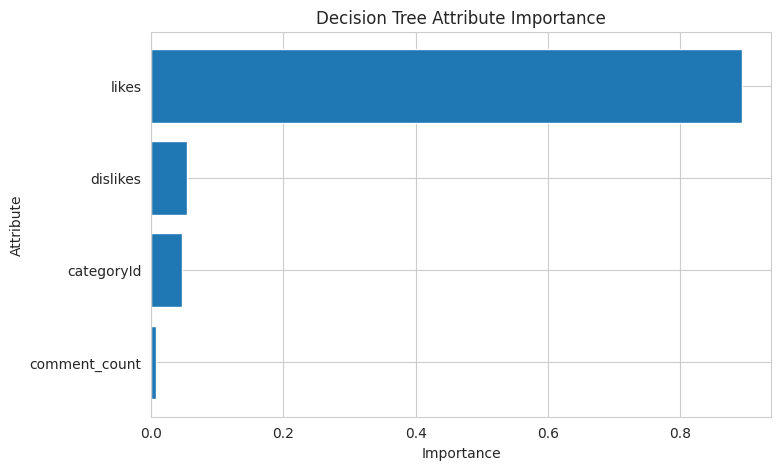

In [65]:
plt.figure(figsize=(8, 5))
plt.barh(importance['Attribute'], importance['Importance'])
plt.xlabel('Importance')
plt.ylabel('Attribute')
plt.title('Decision Tree Attribute Importance')
plt.gca().invert_yaxis()
plt.show()

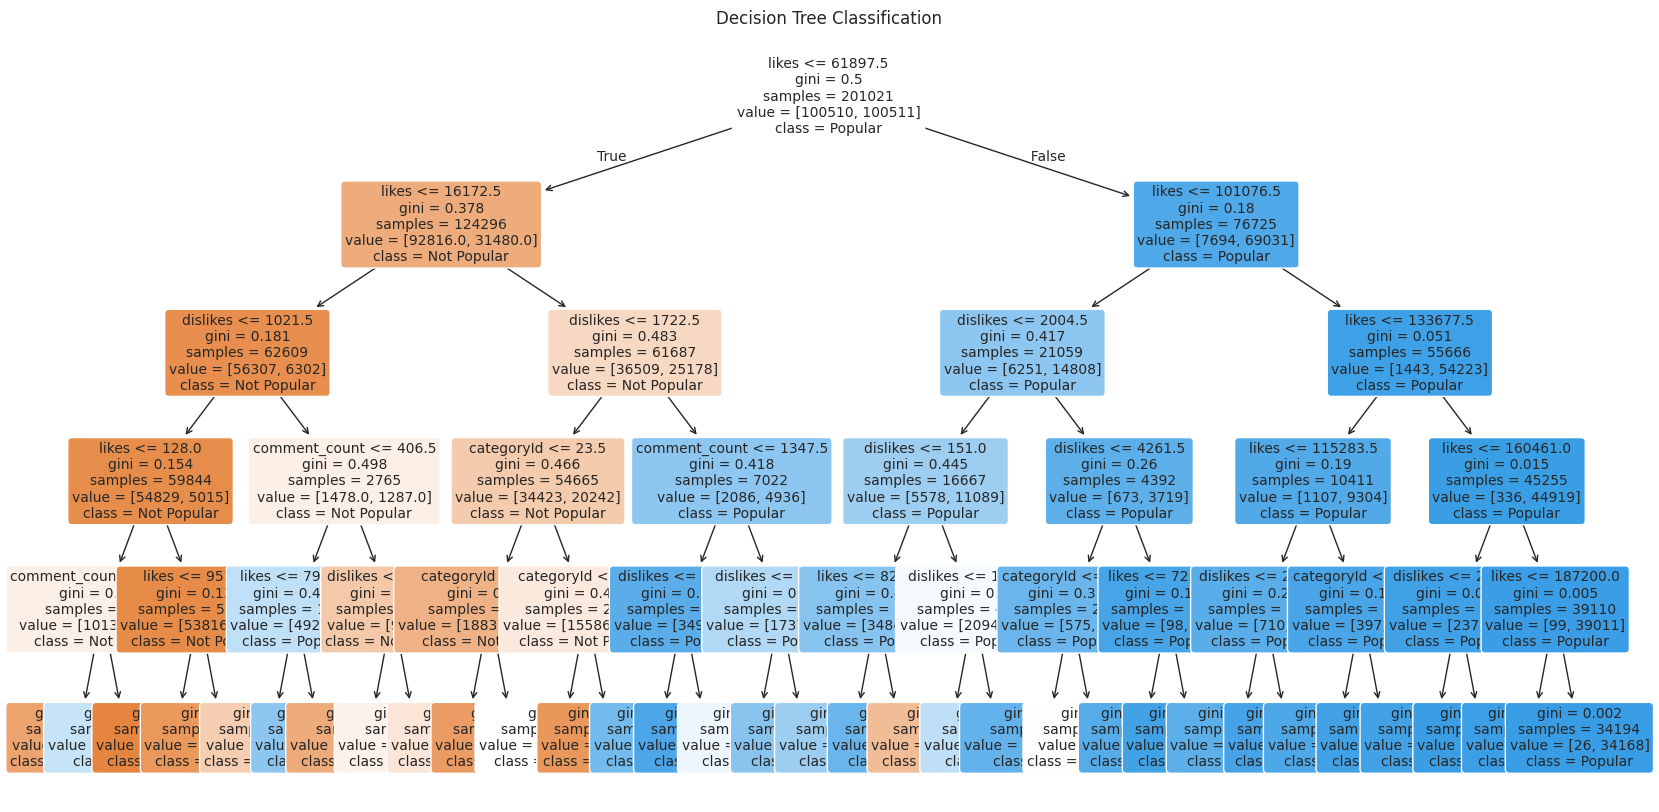

In [66]:
plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree Classification')
plt.show()

In [67]:
new_video = pd.DataFrame({
    'likes': [100000],
    'dislikes': [1000],
    'comment_count': [5000],
    'categoryId': [10]
})

prediction = dt_model.predict(new_video)

print("Predicted Class:", prediction[0])

Predicted Class: Not Popular


In [68]:
print("DECISION TREE CLASSIFICATION RESULTS")
print("------------------------------------")

print("Accuracy:", accuracy * 100, "%")

print("\nAttribute Importance:")
print(importance)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

DECISION TREE CLASSIFICATION RESULTS
------------------------------------
Accuracy: 82.24291626870423 %

Attribute Importance:
       Attribute  Importance
0          likes    0.893341
1       dislikes    0.054081
3     categoryId    0.046003
2  comment_count    0.006574

Classification Report:


              precision    recall  f1-score   support

 Not Popular       0.78      0.90      0.84     25128
     Popular       0.88      0.74      0.81     25128

    accuracy                           0.82     50256
   macro avg       0.83      0.82      0.82     50256
weighted avg       0.83      0.82      0.82     50256



### 8.5 Naïve Bayes Classifier

In [69]:
nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

print("Naïve Bayes model trained successfully!")

Naïve Bayes model trained successfully!


In [70]:
y_pred_nb = nb_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_nb[:10])

First 10 predictions:
['Not Popular' 'Not Popular' 'Popular' 'Not Popular' 'Not Popular'
 'Not Popular' 'Not Popular' 'Popular' 'Not Popular' 'Popular']


In [71]:
comparison_nb = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_nb
})

comparison_nb.head(10)

,Actual,Predicted
0,Popular,Not Popular
1,Popular,Not Popular
2,Popular,Popular
3,Not Popular,Not Popular
4,Not Popular,Not Popular
5,Not Popular,Not Popular
6,Not Popular,Not Popular
7,Popular,Popular
8,Not Popular,Not Popular
9,Popular,Popular


In [72]:
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Naïve Bayes Accuracy:", accuracy_nb)
print("Accuracy (%):", accuracy_nb * 100)

Naïve Bayes Accuracy: 0.7444683221903853
Accuracy (%): 74.44683221903853


In [73]:
cm_nb = confusion_matrix(y_test, y_pred_nb)

print("Confusion Matrix:")
print(cm_nb)

Confusion Matrix:
[[24762   366]
 [12476 12652]]


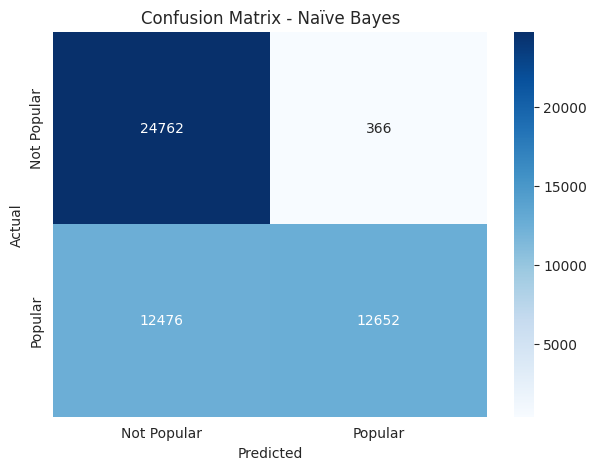

In [74]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_nb, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Not Popular', 'Popular'],
    yticklabels=['Not Popular', 'Popular']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Naïve Bayes')
plt.show()

In [75]:
print("Naïve Bayes Classification Report")
print("----------------------------------")

print(classification_report(y_test, y_pred_nb))

Naïve Bayes Classification Report
----------------------------------


              precision    recall  f1-score   support

 Not Popular       0.66      0.99      0.79     25128
     Popular       0.97      0.50      0.66     25128

    accuracy                           0.74     50256
   macro avg       0.82      0.74      0.73     50256
weighted avg       0.82      0.74      0.73     50256



In [76]:
precision_nb = precision_score(y_test, y_pred_nb, pos_label='Popular')
recall_nb = recall_score(y_test, y_pred_nb, pos_label='Popular')
f1_nb = f1_score(y_test, y_pred_nb, pos_label='Popular')

print("Accuracy :", accuracy_nb)
print("Precision:", precision_nb)
print("Recall   :", recall_nb)
print("F1-Score :", f1_nb)

Accuracy : 0.7444683221903853
Precision: 0.9718850821938854
Recall   : 0.5035020694046483
F1-Score : 0.6633460913332984


In [77]:
nb_results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Score': [accuracy_nb, precision_nb, recall_nb, f1_nb]
})

nb_results

,Metric,Score
0,Accuracy,0.744468
1,Precision,0.971885
2,Recall,0.503502
3,F1-Score,0.663346


### 8.6 Decision Tree vs Naïve Bayes

,Model,Accuracy
0,Decision Tree,0.822429
1,Naïve Bayes,0.744468


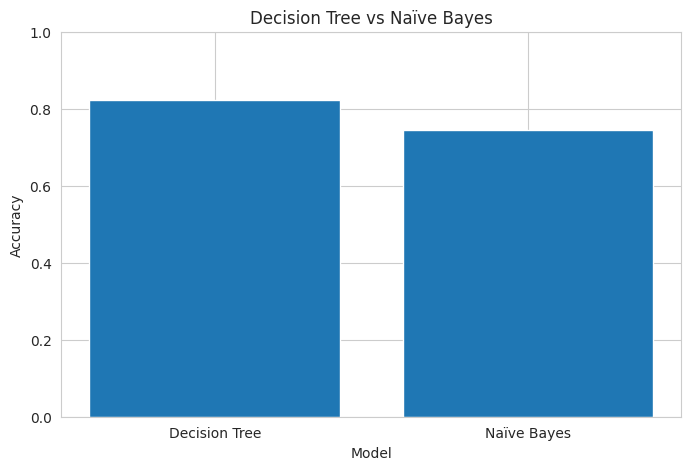

In [78]:
model_comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Naïve Bayes'],
    'Accuracy': [accuracy, accuracy_nb]
})

display(model_comparison)

plt.figure(figsize=(8, 5))
plt.bar(model_comparison['Model'], model_comparison['Accuracy'])
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('Decision Tree vs Naïve Bayes')
plt.ylim(0, 1)
plt.show()

## 9. Clustering – K-Means
We group videos into clusters based on `view_count`, `likes`, `dislikes` and `comment_count`. The data is standardised first because K-Means is distance-based.

In [79]:
# Select numerical attributes for clustering
cluster_df = df[['view_count', 'likes', 'dislikes', 'comment_count']].copy()

# Remove missing values
cluster_df.dropna(inplace=True)

print("Dataset shape:", cluster_df.shape)

cluster_df.head()

Dataset shape: (251277, 4)


,view_count,likes,dislikes,comment_count
0,9885899,224925,3979409,350210
1,11308046,655450,33242,405146
2,9140911,296533,6179,30058
3,23564512,743931,84162,136942
4,6783649,268817,8798,22984


In [80]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(cluster_df)

print("Standardized data:")
print(X_scaled[:5])

Standardized data:
[[1.01610822e+00 2.18049400e-01 5.52378489e+01 4.86876591e+00]
 [1.21986553e+00 1.31020760e+00 4.29293551e-01 5.65092618e+00]
 [9.09370476e-01 3.99704971e-01 5.34138856e-02 3.10549579e-01]
 [2.97590386e+00 1.53466669e+00 1.13652455e+00 1.83232797e+00]
 [5.71635078e-01 3.29394869e-01 8.97893371e-02 2.09832349e-01]]


### 9.1 Elbow Method

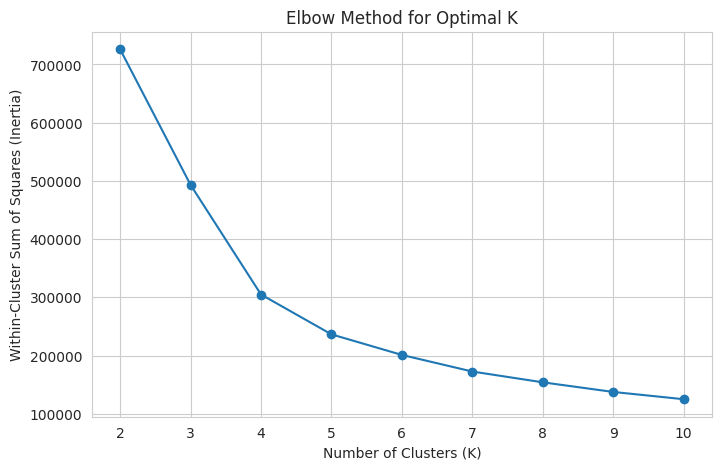

In [81]:
inertia = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (Inertia)')
plt.title('Elbow Method for Optimal K')
plt.show()

### 9.2 Silhouette Score (choosing K)

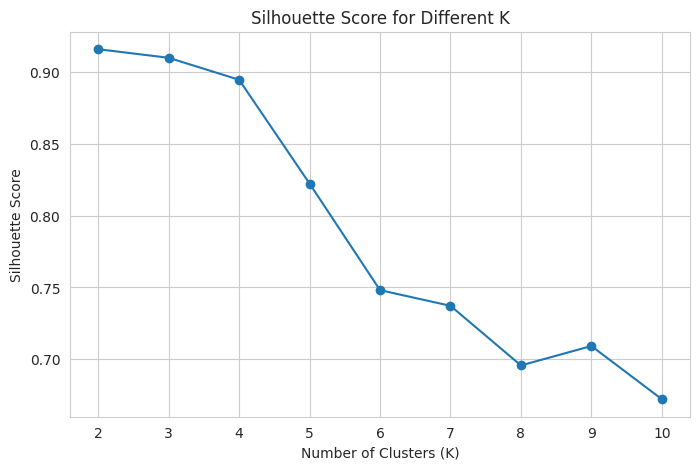

Silhouette scores: {2: np.float64(0.9157), 3: np.float64(0.9097), 4: np.float64(0.8944), 5: np.float64(0.8222), 6: np.float64(0.7481), 7: np.float64(0.7372), 8: np.float64(0.6958), 9: np.float64(0.7093), 10: np.float64(0.6723)}
K with highest silhouette score: 2


In [82]:
# Silhouette on a random sample (computing it on every row would be very slow)
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_scaled), size=10000, replace=False)
X_sample = X_scaled[sample_idx]

sil_scores = []
for k in K_range:
    labels_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_sample, labels_k[sample_idx]))

plt.figure(figsize=(8, 5))
plt.plot(K_range, sil_scores, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different K')
plt.show()

best_k = list(K_range)[int(np.argmax(sil_scores))]
print("Silhouette scores:", dict(zip(K_range, np.round(sil_scores, 4))))
print("K with highest silhouette score:", best_k)

### 9.3 Final K-Means Model

In [83]:
# Final K-Means model. K is chosen using the elbow plot and the silhouette scores above.
K_FINAL = 4

kmeans_final = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
cluster_df['cluster'] = kmeans_final.fit_predict(X_scaled)

print("Silhouette score (sample):",
      silhouette_score(X_sample, cluster_df['cluster'].values[sample_idx]))
print("\nVideos per cluster:")
print(cluster_df['cluster'].value_counts().sort_index())

Silhouette score (sample): 0.8944141614772603

Videos per cluster:
cluster
0    244643
1        10
2        92
3      6532
Name: count, dtype: int64


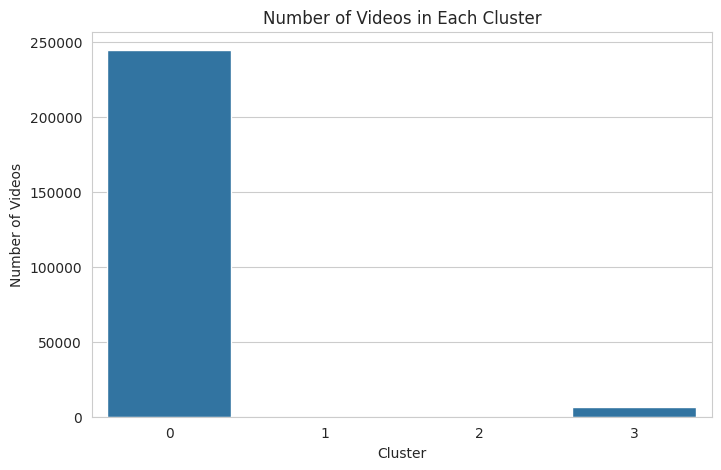

In [84]:
plt.figure(figsize=(8, 5))
sns.countplot(data=cluster_df, x='cluster')
plt.title('Number of Videos in Each Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Videos')
plt.show()

### 9.4 Cluster Profiles

In [85]:
cluster_profile = cluster_df.groupby('cluster').mean().round(0)
cluster_profile['video_count'] = cluster_df['cluster'].value_counts().sort_index()

cluster_profile

,view_count,likes,dislikes,comment_count,video_count
cluster,,,,,
0,1957617.0,94770.0,1354.0,4688.0,244643
1,54721590.0,605239.0,10993353.0,968686.0,10
2,108074470.0,8662395.0,179367.0,2975296.0,92
3,32551278.0,1673663.0,19698.0,98233.0,6532


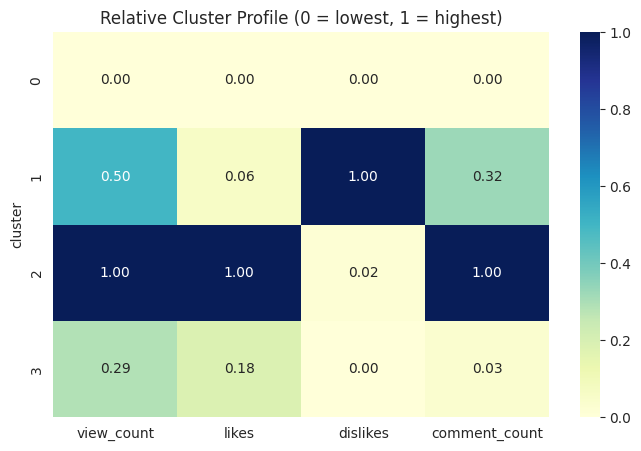

In [86]:
profile_scaled = cluster_df.groupby('cluster')[['view_count', 'likes', 'dislikes', 'comment_count']].mean()
profile_scaled = (profile_scaled - profile_scaled.min()) / (profile_scaled.max() - profile_scaled.min())

plt.figure(figsize=(8, 5))
sns.heatmap(profile_scaled, annot=True, cmap='YlGnBu', fmt='.2f')
plt.title('Relative Cluster Profile (0 = lowest, 1 = highest)')
plt.show()

### 9.5 Cluster Visualisation (PCA)

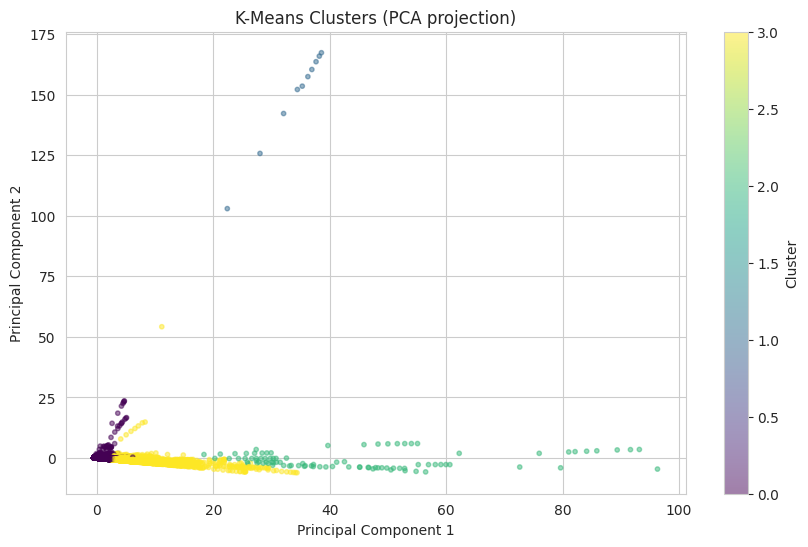

Variance explained by 2 components: 0.8178068569934851


In [87]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=cluster_df['cluster'], cmap='viridis', alpha=0.5, s=10
)
plt.colorbar(scatter, label='Cluster')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clusters (PCA projection)')
plt.show()

print("Variance explained by 2 components:", pca.explained_variance_ratio_.sum())

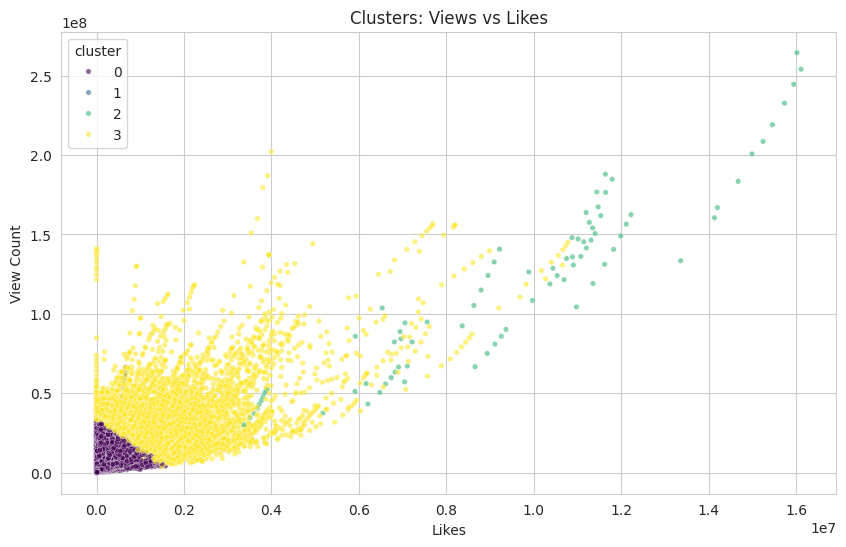

In [88]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=cluster_df, x='likes', y='view_count',
    hue='cluster', palette='viridis', alpha=0.6, s=15
)
plt.title('Clusters: Views vs Likes')
plt.xlabel('Likes')
plt.ylabel('View Count')
plt.show()

## 10. Overall Conclusion
* **Regression:** Likes alone explain about 63% of the variance in views (R² ≈ 0.63). Adding dislikes and comment count improves R² only slightly (≈ 0.635), so likes are by far the most useful predictor.
* **Classification:** The Decision Tree (depth 5) reached about 82% accuracy and clearly beat Naïve Bayes at about 74%. Naïve Bayes is very precise for "Popular" (≈ 0.97) but misses half of the popular videos (recall ≈ 0.50). Likes carry about 89% of the Decision Tree's feature importance.
* **Clustering:** K-Means on the standardised data finds one large "typical" cluster (about 244k rows, around 2 million views) and a few small clusters made of extremely viral videos or videos with abnormal dislike counts. The silhouette score favours a small K (K = 2 is highest), which shows that the clusters are driven by the heavy outliers; K = 4 was kept to give a richer profile. Applying a log transform or removing outliers before clustering would be a good next step.
* **Overall:** Trending videos in India are dominated by entertainment content and by a small set of repeat channels, and popularity is driven mainly by likes.